# Safe Motion Planning and Fallback

**Module 07 · Runtime Assurance and Operations** · Notebook 2 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/07_Runtime_Assurance_and_Operations/02_safe_motion_planning_and_fallback.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [Criticality metrics and RSS](../04_SOTIF_ISO21448/05_criticality_metrics_and_rss.ipynb), [ODD and runtime monitoring](01_odd_and_runtime_monitoring.ipynb), [Trajectory prediction](../01_Perception/09_trajectory_prediction.ipynb); polynomials, NumPy | ISO 21448:2022, ISO 26262:2018, UN R157 (01 series), ISO 23793-1:2024, IEEE 2846-2022, UL 4600 (3rd ed., 2023) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After this notebook you will be able to:

1. Place **route, behaviour and motion planning** in an automated driving stack and state which safety properties each layer can and cannot provide.
2. Implement a **sampling-based Frenet lattice planner** (quintic lateral and quartic longitudinal polynomials) from scratch, and separate **soft costs** from **hard safety constraints**.
3. Quantify the error of a constant-velocity **prediction on real NGSIM trajectories** and use it as an **inflated occupancy** or a **chance constraint**, including the "freezing robot" failure of over-conservative constraints.
4. Build an **RSS safety shield** (the same envelope as `avsafety.sotif`) in a **Simplex** arrangement over a nominal planner, and measure its effect on collisions, minimum TTC, jerk and progress in closed loop with **real US-101 traffic**.
5. Design **minimal risk manoeuvres**, derive comfort limits from **real KITTI GPS/IMU data**, and quantify how an emergency stop shifts risk to following traffic, using real follower gaps.
6. Distinguish **fail-safe** and **fail-operational** architectures and compare them in a fault-injection experiment.

## 1. Where planning sits, and what each layer can promise

A modular automated driving system usually splits planning into three layers (Paden et al., 2016):

| Layer | Question | Typical method | Horizon / rate | Safety contribution | What it cannot guarantee |
|---|---|---|---|---|---|
| **Route planning** | Which roads? | Graph search on the map (Dijkstra, A*, contraction hierarchies) | Whole trip, re-planned on events | Keeps the trip inside the ODD (road types, mapped area, closures) | Anything about traffic participants |
| **Behaviour (decision) planning** | Follow, change lane, yield, stop? | State machines, rule sets, scenario-specific logic, increasingly learned policies | 5–15 s, ~1–10 Hz | Encodes traffic rules and right of way; selects a *safe manoeuvre class* | Feasibility of the exact trajectory |
| **Motion (trajectory) planning** | Exactly which path and speed profile? | Sampling (lattices), optimisation (MPC), graph search over states | 3–8 s, ~10 Hz | Kinematic feasibility, collision avoidance with *predicted* agents, comfort | Correctness of the predictions it relies on |

Below the motion planner, a **trajectory-tracking controller** turns the trajectory into steering and acceleration commands. A **safety layer** (monitor, envelope, shield) can sit at the interface between motion planning and control: it does not choose *what* to do, it vetoes or replaces what is unsafe. This notebook builds that interface on real traffic.

**Why the motion planner is safety-relevant in ISO 21448 terms.** The planner is where perception and prediction insufficiencies turn into vehicle behaviour. A wrong prediction (a functional insufficiency) only becomes hazardous behaviour if the planner commits to a trajectory that leaves no margin for it. Hard constraints, envelopes and fallback trajectories are therefore SOTIF measures as much as planning features.

## 2. Data and licence

We need traffic that real drivers produced, so that the surrounding agents brake, accelerate and change lanes the way people do. We use 50 s of the **NGSIM US-101** data set (Los Angeles, 15 June 2005, 08:20–08:21 local time, congested morning peak): every vehicle on a ~640 m, five-lane motorway section recorded by cameras at 10 Hz. NGSIM uses **feet, ft/s and milliseconds**; we convert to SI units on loading. The raw positions contain measurement noise, which is well documented (Coifman & Li, 2017); we treat this as part of the realism the planner must cope with.

For comfort limits we use the GPS/IMU (OXTS) records of the 21 **KITTI tracking** training sequences (Karlsruhe, human driver).

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety.sotif import rss_safe_longitudinal_distance, time_to_collision

import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

T0 = time.time()
rng = np.random.default_rng(42)
FT = 0.3048                      # NGSIM feet -> metres
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "red": "#D55E00", "purple": "#CC79A7", "black": "#000000"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print(D.attribution("NGSIM", "KITTI"))

Data: US DOT Next Generation Simulation (NGSIM) vehicle trajectories, public domain, https://data.transportation.gov/d/8ect-6jqj
Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


In [2]:
T_START = 1118848800000          # 15 June 2005 08:20:00 PDT, in ms since the epoch (NGSIM global_time)
WINDOW_MS = 50_000               # 50 s of traffic
try:
    raw = D.ngsim("us-101", where=f"global_time >= {T_START} AND global_time < {T_START + WINDOW_MS}",
                  select="vehicle_id,global_time,local_x,local_y,v_length,v_width,v_vel,lane_id")
except D.DataUnavailable as exc:
    raise SystemExit(f"NGSIM could not be downloaded ({exc}). This notebook needs the real trajectories.")

ng = pd.DataFrame({
    "id": raw.vehicle_id.astype(int),
    "k": ((raw.global_time - T_START) // 100).astype(int),   # 10 Hz step index
    "s": raw.local_y * FT,           # front bumper along the road [m]
    "d": raw.local_x * FT,           # lateral position of the vehicle centre from the left road edge [m]
    "L": raw.v_length * FT, "W": raw.v_width * FT,
    "v": raw.v_vel * FT,             # speed [m/s]
    "lane": raw.lane_id.astype(int),
})
ng = ng[ng.lane <= 6].sort_values(["id", "k"]).reset_index(drop=True)   # main lanes 1-5 and auxiliary lane 6
NK = WINDOW_MS // 100
LANE_C = ng[ng.lane <= 5].groupby("lane").d.median().to_numpy()       # measured lane centres, lanes 1..5
LANE_W = float(np.median(np.diff(LANE_C)))

# dense [vehicle, step] arrays; NaN where a vehicle is not in the section
ids = np.sort(ng.id.unique()); idx = {v: i for i, v in enumerate(ids)}; NV = len(ids)
S, Dl, V = (np.full((NV, NK), np.nan) for _ in range(3))
Lv, Wv = np.zeros(NV), np.zeros(NV)
r = ng.id.map(idx).to_numpy()
S[r, ng.k], Dl[r, ng.k], V[r, ng.k] = ng.s, ng.d, ng.v
Lv[r], Wv[r] = ng.L, ng.W
VD_PAST = np.full_like(Dl, np.nan)                 # lateral speed from the PAST 1 s only (no look-ahead)
VD_PAST[:, 10:] = Dl[:, 10:] - Dl[:, :-10]
ROAD_END = float(np.nanmax(S))

print(f"{len(ng):,} trajectory samples of {NV} vehicles over {NK / 10:.0f} s; section length {ROAD_END:.0f} m")
print("Lane centres [m]:", LANE_C.round(2), f"-> lane width {LANE_W:.2f} m")
print(f"Speed: median {np.nanmedian(V):.1f} m/s ({np.nanmedian(V) * 3.6:.0f} km/h), "
      f"5th-95th percentile {np.nanpercentile(V, 5):.1f}-{np.nanpercentile(V, 95):.1f} m/s")

74,794 trajectory samples of 272 vehicles over 50 s; section length 666 m
Lane centres [m]: [ 2.19  5.68  9.14 12.49 16.1 ] -> lane width 3.48 m
Speed: median 10.4 m/s (38 km/h), 5th-95th percentile 6.7-13.7 m/s


### 2.1 How close do real drivers follow, measured with RSS?

Before using RSS as a shield, we check it against the drivers in the data. For every vehicle and every 0.5 s we find its leader in the same lane and compare the bumper-to-bumper gap with the RSS minimum safe distance (`avsafety.sotif.rss_safe_longitudinal_distance`, default parameters $\rho = 0.5$ s, $a_{\max} = 2$, $b_{\min} = 4$, $b_{\max} = 8$ m/s²; derivation in [04/05](../04_SOTIF_ISO21448/05_criticality_metrics_and_rss.ipynb)).

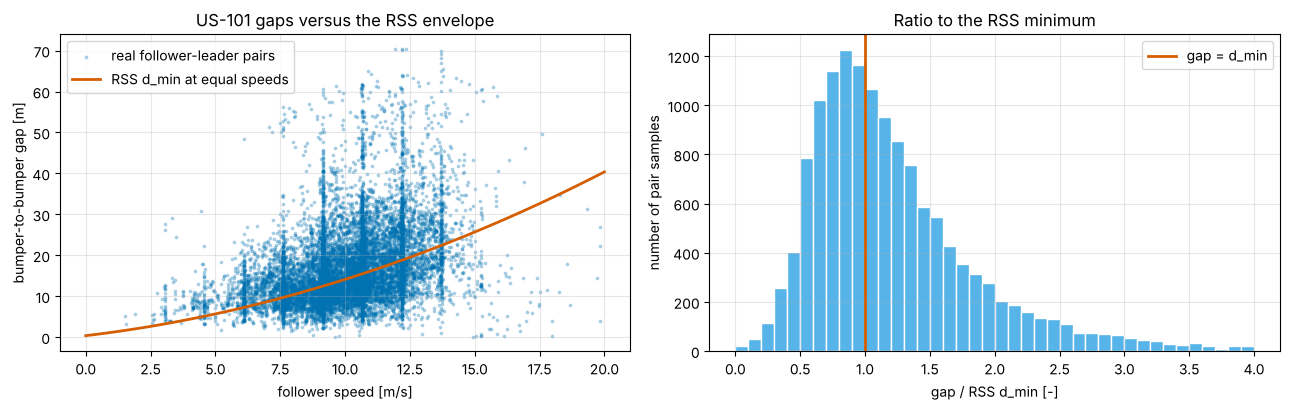

14,033 follower-leader samples. Median time gap 1.50 s. Share of samples with gap >= RSS d_min: 56%.


In [3]:
pairs = []
for k in range(0, NK, 5):
    snap = ng[ng.k == k].sort_values("s")
    for lane, g in snap[snap.lane <= 5].groupby("lane"):
        s_, L_, v_ = g.s.to_numpy(), g.L.to_numpy(), g.v.to_numpy()
        for i in range(len(g) - 1):                       # follower i, leader i+1
            pairs.append((k, lane, s_[i + 1] - L_[i + 1] - s_[i], v_[i], v_[i + 1]))
pairs = pd.DataFrame(pairs, columns=["k", "lane", "gap", "v_f", "v_l"])
pairs = pairs[(pairs.gap > 0) & (pairs.gap < 120) & (pairs.v_f > 1.0)]
pairs["d_min"] = [rss_safe_longitudinal_distance(a, b) for a, b in zip(pairs.v_f, pairs.v_l)]
pairs["time_gap"] = pairs.gap / pairs.v_f
share_ok = (pairs.gap >= pairs.d_min).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(pairs.v_f, pairs.gap, s=3, alpha=0.25, color=OI["blue"], label="real follower-leader pairs")
vv = np.linspace(0, 20, 50)
ax[0].plot(vv, [rss_safe_longitudinal_distance(x, x) for x in vv], color=OI["red"], lw=2, label="RSS d_min at equal speeds")
ax[0].set(xlabel="follower speed [m/s]", ylabel="bumper-to-bumper gap [m]", title="US-101 gaps versus the RSS envelope")
ax[0].legend()
ax[1].hist(pairs.gap / pairs.d_min, bins=np.linspace(0, 4, 41), color=OI["sky"], edgecolor="white")
ax[1].axvline(1.0, color=OI["red"], lw=2, label="gap = d_min")
ax[1].set(xlabel="gap / RSS d_min [-]", ylabel="number of pair samples", title="Ratio to the RSS minimum")
ax[1].legend(); plt.tight_layout(); plt.show()
print(f"{len(pairs):,} follower-leader samples. Median time gap {pairs.time_gap.median():.2f} s. "
      f"Share of samples with gap >= RSS d_min: {share_ok:.0%}.")

With the toolkit's default parameters, a large share of the real follower samples in congested US-101 traffic lie **inside** the RSS minimum distance (the printed share is the complement). This does not mean those drivers were driving dangerously; it means the default worst-case assumptions ($b_{\max} = 8$ m/s² for the leader, only $b_{\min} = 4$ m/s² guaranteed for the follower, 0.5 s response) are far more conservative than what drivers accept in dense traffic. For a shield this has two consequences we will see in closed loop: frequent interventions, and lost progress whenever the ego is asked to keep longer gaps than the surrounding traffic. Parameter choice is a safety-case decision (IEEE 2846-2022 addresses which assumptions about other road users are reasonably foreseeable), not a tuning detail.

## 3. Predictions with uncertainty

A motion planner checks candidate trajectories against **predicted** positions of other agents. The simplest predictor, used by many safety checks because it is transparent, is **constant velocity (CV)**: longitudinal position $s(t+h) = s(t) + v\,h$; lateral position extrapolated only if the lateral speed over the last second exceeds a gate (here 0.5 m/s), and by at most one lane. Learned predictors are covered in [01/09](../01_Perception/09_trajectory_prediction.ipynb); what matters here is that *every* predictor has an error distribution that grows with the horizon, and that we can **measure** it on real data.

,q50_s,q95_s,q99_s,q50_d,q95_d,q99_d
horizon [s],,,,,,
0.5,0.05,0.34,0.49,0.03,0.21,0.35
1.0,0.20,0.97,1.38,0.07,0.39,0.66
2.0,0.72,2.60,3.71,0.14,0.62,1.24
3.0,1.50,4.91,6.98,0.19,0.77,1.88
5.0,3.50,11.04,15.14,0.25,0.97,2.85


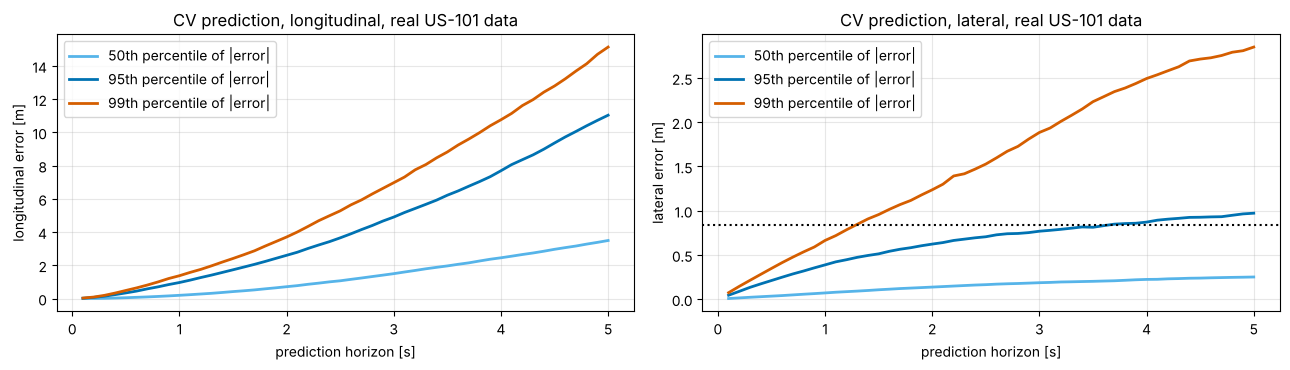

330,713 prediction samples. At 3 s the 95th-percentile error is 4.9 m longitudinally and 0.77 m laterally; at 5 s 11.0 m and 0.97 m.


In [4]:
VD_GATE = 0.5          # m/s; slower lateral motion is treated as measurement noise

def lateral_pred(d0, vd, h):
    # Lane-aware constant velocity: lateral motion only above the gate, at most one lane width
    vd = np.where(np.abs(vd) > VD_GATE, vd, 0.0)
    return d0 + np.clip(vd * h, -LANE_W, LANE_W)

def cv_errors(horizons, stride=10):
    # Prediction error of every vehicle, starting every `stride` steps, using only past information
    rows = []
    for h in horizons:
        hk = int(round(h * 10))
        for k0 in range(10, NK - hk, stride):
            ok = ~np.isnan(S[:, k0]) & ~np.isnan(S[:, k0 + hk]) & ~np.isnan(VD_PAST[:, k0])
            rows.append(pd.DataFrame({"h": h,
                                      "e_s": S[ok, k0 + hk] - (S[ok, k0] + V[ok, k0] * h),
                                      "e_d": Dl[ok, k0 + hk] - lateral_pred(Dl[ok, k0], VD_PAST[ok, k0], h)}))
    return pd.concat(rows, ignore_index=True)

HORIZONS = np.round(np.arange(0.1, 5.01, 0.1), 1)
err = cv_errors(HORIZONS)
q = err.groupby("h").agg(**{f"{p}{qq}_{ax}": (f"e_{ax}", (lambda x, qq=qq: np.quantile(np.abs(x), qq / 100)))
                           for ax in ("s", "d") for qq in (50, 95, 99) for p in ["q"]})
display(q.loc[[0.5, 1.0, 2.0, 3.0, 5.0]].round(2).rename_axis("horizon [s]"))

# Empirical survival functions P(|error| > x) per horizon, on a grid, for the chance constraint
G_S, G_D = np.arange(0, 40.01, 0.1), np.arange(0, 6.001, 0.02)
SF_S = np.array([[np.mean(np.abs(g.e_s.to_numpy()) > x) for x in G_S] for _, g in err.groupby("h")])
SF_D = np.array([[np.mean(np.abs(g.e_d.to_numpy()) > x) for x in G_D] for _, g in err.groupby("h")])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a_, axn, unit in [(ax[0], "s", "longitudinal"), (ax[1], "d", "lateral")]:
    for qq, c in [(50, OI["sky"]), (95, OI["blue"]), (99, OI["red"])]:
        a_.plot(q.index, q[f"q{qq}_{axn}"], color=c, lw=2, label=f"{qq}th percentile of |error|")
    a_.set(xlabel="prediction horizon [s]", ylabel=f"{unit} error [m]", title=f"CV prediction, {unit}, real US-101 data")
    a_.legend()
ax[1].axhline(LANE_W / 2 - 0.9, color=OI["black"], ls=":", label="free space beside a car in its lane")
plt.tight_layout(); plt.show()
print(f"{len(err):,} prediction samples. At 3 s the 95th-percentile error is {q.loc[3.0, 'q95_s']:.1f} m longitudinally "
      f"and {q.loc[3.0, 'q95_d']:.2f} m laterally; at 5 s {q.loc[5.0, 'q95_s']:.1f} m and {q.loc[5.0, 'q95_d']:.2f} m.")

Two ways to use such an error model in planning:

- **Inflated occupancy.** Grow each predicted vehicle box by a quantile of the error at that horizon. Simple and conservative, but quantiles of the two axes combined in a box over-cover, and the inflation grows to more than a lane width in a few seconds.
- **Chance constraint.** Require the probability of overlap with each agent at each time to stay below $\delta$ (Blackmore et al., 2011, for the formal treatment). With the empirical survival functions above and the assumption that longitudinal and lateral errors are independent, $P(\text{overlap}) \approx P(|e_s| > g_s)\,P(|e_d| > g_d)$ for longitudinal and lateral clearances $g_s, g_d$.

Both are only as good as the data behind the error model: these errors come from 50 s of one congested motorway. A safety argument has to show that the error distribution used at runtime is valid for the ODD (traffic density, road type, the actual predictor), which is a SOTIF validation activity in its own right.

## 4. A Frenet lattice planner from scratch

We plan in road-aligned **Frenet coordinates**: arc length $s$ along the lane and lateral offset $d$. The road section is straight, so Frenet and Cartesian coordinates coincide up to a shift; on curved roads the same planner works after projecting the agents onto the reference line. Following Werling et al. (2010):

- **Lateral motion** is a quintic polynomial $d(t)$ from the current state $(d_0, \dot d_0, \ddot d_0)$ to a lane centre with zero lateral speed and acceleration at time $T$. A quintic minimises the integral of squared jerk for these boundary conditions.
- **Longitudinal motion** is a quartic $s(t)$ that reaches a target speed $v_T$ with zero acceleration at $T$ (velocity keeping; the end position is free).
- The **lattice** is the set of end states: {current lane, left, right} × target speeds × $T \in \{3, 4, 5\}$ s. Beyond $T$ the trajectory holds speed and lane until the 5 s horizon.

The coefficients follow from the boundary conditions in closed form; the cell checks them numerically.

In [5]:
def quintic(x0, v0, a0, x1, v1, a1, T):
    # Coefficients c0..c5 of the quintic from (x0, v0, a0) at t=0 to (x1, v1, a1) at t=T; arrays allowed
    x0, v0, a0, x1, v1, a1, T = np.broadcast_arrays(*map(np.asarray, (x0, v0, a0, x1, v1, a1, T)))
    h = x1 - x0
    c3 = (20*h - (8*v1 + 12*v0)*T - (3*a0 - a1)*T**2) / (2*T**3)
    c4 = (-30*h + (14*v1 + 16*v0)*T + (3*a0 - 2*a1)*T**2) / (2*T**4)
    c5 = (12*h - 6*(v1 + v0)*T + (a1 - a0)*T**2) / (2*T**5)
    return np.stack([x0, v0, 0.5*a0, c3, c4, c5], axis=-1).astype(float)

def quartic(x0, v0, a0, v1, a1, T):
    # Velocity keeping: end speed v1 and end acceleration a1 at t=T, end position free
    x0, v0, a0, v1, a1, T = np.broadcast_arrays(*map(np.asarray, (x0, v0, a0, v1, a1, T)))
    dv, da = v1 - v0 - a0*T, a1 - a0
    c3 = (3*dv - T*da) / (3*T**2)
    c4 = (T*da - 2*dv) / (4*T**3)
    return np.stack([x0, v0, 0.5*a0, c3, c4, np.zeros_like(c3)], axis=-1).astype(float)

def eval_poly(C, t):
    # Position, velocity, acceleration, jerk of polynomials (rows of C) at times t (rows of t)
    C = np.atleast_2d(C); c = [C[:, [i]] for i in range(6)]
    p = c[0] + c[1]*t + c[2]*t**2 + c[3]*t**3 + c[4]*t**4 + c[5]*t**5
    v = c[1] + 2*c[2]*t + 3*c[3]*t**2 + 4*c[4]*t**3 + 5*c[5]*t**4
    a = 2*c[2] + 6*c[3]*t + 12*c[4]*t**2 + 20*c[5]*t**3
    j = 6*c[3] + 24*c[4]*t + 60*c[5]*t**2
    return p, v, a, j

_q = eval_poly(quintic(1.0, 2.0, 0.5, 4.0, 0.0, 0.0, 3.0), np.array([[3.0]]))
assert np.allclose([x[0, 0] for x in _q[:3]], [4.0, 0.0, 0.0])
_q = eval_poly(quartic(0.0, 10.0, 1.0, 15.0, 0.0, 4.0), np.array([[4.0]]))
assert np.allclose([x[0, 0] for x in _q[1:3]], [15.0, 0.0])

DT, HOR = 0.1, 5.0
TS = np.arange(1, int(round(HOR / DT)) + 1) * DT        # 0.1 ... 5.0 s
T_SET = (3.0, 4.0, 5.0)
EGO_L, EGO_W = 4.5, 1.8

def lane_of(d):
    return int(np.argmin(np.abs(LANE_C - d)))

def lattice(ego, v_des):
    # All candidates as arrays (one row each). ego = (s, v, a, d, d_dot, d_ddot)
    s0, v0, a0, d0, dv0, da0 = ego
    cur = lane_of(d0)
    speeds = np.unique(np.clip([0.0, v0 - 4, v0 - 2, v0, v0 + 2, v_des], 0.0, v_des).round(2))
    lanes = [l for l in (cur - 1, cur, cur + 1) if 0 <= l < len(LANE_C)]
    Tc, vt, ln = (g.ravel() for g in np.meshgrid(T_SET, speeds, lanes, indexing="ij"))
    tt = np.minimum(TS[None, :], Tc[:, None])
    s, sv, sa, sj = eval_poly(quartic(s0, v0, a0, vt, 0.0, Tc), tt)
    d, dv, da, dj = eval_poly(quintic(d0, dv0, da0, LANE_C[ln], 0.0, 0.0, Tc), tt)
    tail = TS[None, :] > Tc[:, None]
    s = np.where(tail, s + sv * (TS[None, :] - Tc[:, None]), s)
    z = lambda x: np.where(tail, 0.0, x)
    return dict(T=Tc, v_t=vt, lane=ln, cur=np.full(len(Tc), cur), s=s, v=sv, a=z(sa), j=z(sj),
                d=d, dv=z(dv), da=z(da), dj=z(dj))

def pick(c, i):
    return {k: v[i] for k, v in c.items()}

print("closed-form polynomial coefficients verified against their boundary conditions")

closed-form polynomial coefficients verified against their boundary conditions


### 4.1 Soft costs versus hard constraints

| | Hard constraints (reject the candidate) | Soft costs (rank the remaining ones) |
|---|---|---|
| **What** | Kinematic limits ($a \le 2$, $a \ge -4$ m/s², $|\ddot d| \le 1.5$ m/s², $v \ge 0$); no overlap with predicted agents; in the shielded variant, the RSS envelope | Integrated squared jerk, manoeuvre duration, deviation from desired speed, lane changes, proximity |
| **Why** | Safety and physical feasibility must not be traded against comfort | Comfort and progress are negotiable |
| **Failure mode** | If *no* candidate satisfies them, the planner needs a defined **fallback** | Weights tuned on one data set can produce odd behaviour on another; a proximity *cost* is not a safety guarantee |

The principle matters for the safety case: a safety requirement implemented as a weighted cost term can always be outweighed by another term, and its effect cannot be verified independently. The limits used here (2 m/s² acceleration, 4 m/s² braking, 1.5 m/s² lateral) are checked against real human driving in Section 8.

In [6]:
LIMITS = dict(a_acc=2.0, a_dec=4.0, a_lat=1.5)            # comfort limits for nominal driving [m/s^2]
RSS = dict(rho=0.5, a_max_accel=2.0, b_min_brake=4.0, b_max_brake=8.0)   # avsafety.sotif defaults
DELTA = 0.01                                               # chance-constraint level (Section 7)

def feasible(c):
    return ((c["a"].max(1) <= LIMITS["a_acc"] + 1e-6) & (c["a"].min(1) >= -LIMITS["a_dec"] - 1e-6)
            & (np.abs(c["da"]).max(1) <= LIMITS["a_lat"] + 1e-6) & (c["v"].min(1) >= -0.05))

def predict(w, ego):
    # CV prediction of agents within 100 m. Vehicles directly behind the ego in its lane are not collision-
    # checked: keeping their distance is their responsibility (RSS rule 1). They still count for lane changes.
    present = ~np.isnan(w["s"]) & (np.abs(w["s"] - ego[0]) < 100)
    follower = (np.abs(w["d"] - ego[3]) < 0.5 * (Wv + EGO_W)) & (w["s"] < ego[0] - EGO_L)
    a = np.flatnonzero(present & ~follower)
    ps = w["s"][a, None] + w["v"][a, None] * TS[None, :]
    pd_ = lateral_pred(w["d"][a, None], w["vd"][a, None], TS[None, :])
    return a, ps, pd_, np.flatnonzero(present & follower)

def clearance(c, a, ps, pd_, constraint):
    # Per candidate: constraint violated?, smallest longitudinal clearance [m] to laterally close agents
    n = len(c["T"])
    if len(a) == 0:
        return np.zeros(n, bool), np.full(n, 50.0)
    Sc, Dc = c["s"][:, None, :], c["d"][:, None, :]
    long_sep = np.maximum((ps - Lv[a, None])[None] - Sc, (Sc - EGO_L) - ps[None])
    lat_sep = np.abs(pd_[None] - Dc) - 0.5 * (Wv[a, None] + EGO_W)[None]
    clr = np.where(lat_sep < 0.5, long_sep, 50.0).min(axis=(1, 2))
    if constraint == "deterministic":          # fixed margins: 0.5 m longitudinal, 0.1 m lateral
        hit = ((long_sep < 0.5) & (lat_sep < 0.1)).any(axis=(1, 2))
    else:                                      # chance constraint with the empirical error distributions
        ti = np.arange(len(TS))[None, None, :]
        p_s = np.where(long_sep < 0, 1.0, SF_S[ti, np.clip(np.round(long_sep / 0.1).astype(int), 0, len(G_S) - 1)])
        p_d = np.where(lat_sep < 0, 1.0, SF_D[ti, np.clip(np.round(lat_sep / 0.02).astype(int), 0, len(G_D) - 1)])
        hit = (p_s * p_d > DELTA).any(axis=(1, 2))
    return hit, clr

def cost(c, v_des, clr):
    jerk = np.sum(c["j"] ** 2 + c["dj"] ** 2, axis=1) * DT
    return (0.05 * jerk + 1.0 / c["T"] + 0.5 * (v_des - c["v"][:, -1]) ** 2
            + 1.0 * (c["lane"] != c["cur"]) + 20.0 / (1.0 + np.maximum(clr, 0.0)))

### 4.2 One planning cycle on a real traffic snapshot

We place the ego vehicle in the position of a real vehicle (which we remove from the scene) and plan once. Each line is one candidate trajectory; grey candidates violate a kinematic limit, red ones collide with a predicted vehicle, the others are coloured by cost.

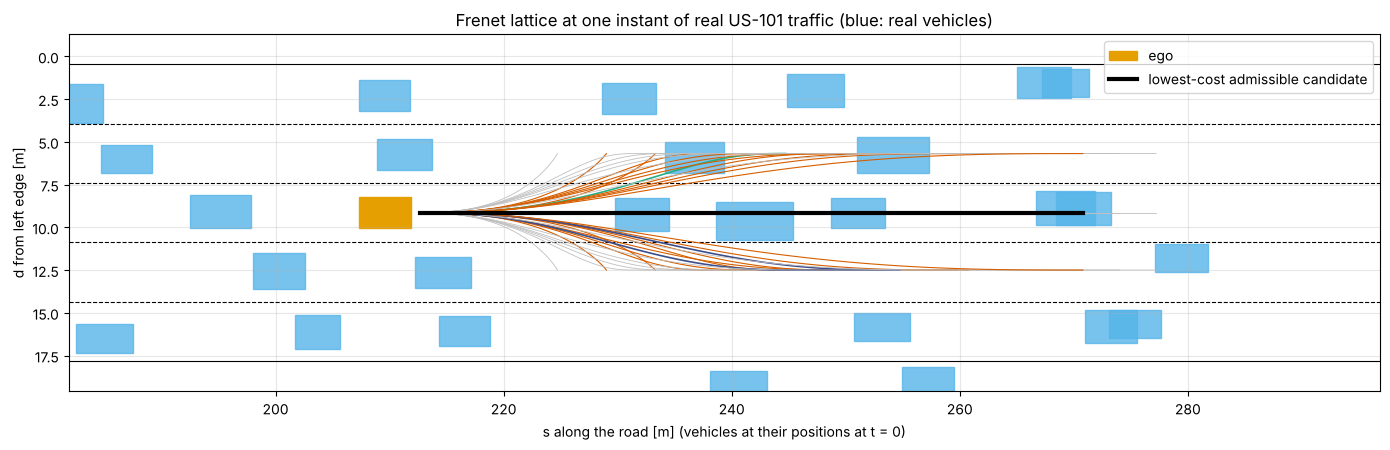

54 candidates: 17 kinematically infeasible, 19 colliding, 18 admissible. Chosen: lane 3, target speed 15.0 m/s, T = 5 s.


In [7]:
EGO_ID = 18                                              # a real vehicle in lane 4, replaced by the ego
e0 = idx[EGO_ID]
ego0 = np.array([S[e0, 0], V[e0, 0], 0.0, LANE_C[lane_of(Dl[e0, 0])], 0.0, 0.0])
w0 = {"s": S[:, 0].copy(), "v": V[:, 0].copy(), "d": Dl[:, 0].copy(), "vd": np.nan_to_num(VD_PAST[:, 0])}
w0["s"][e0] = np.nan
a_, ps_, pd0_, fol_ = predict(w0, ego0)
cand = lattice(ego0, v_des=15.0)
ok = feasible(cand)
hit, clr = clearance(cand, a_, ps_, pd0_, "deterministic")
J = cost(cand, 15.0, clr)

fig, ax = plt.subplots(figsize=(14, 4.6))
for l in range(len(LANE_C) + 1):
    yb = (LANE_C[0] - LANE_W / 2) + l * LANE_W
    ax.axhline(yb, color=OI["black"], lw=0.8, ls="-" if l in (0, len(LANE_C)) else "--")
present = np.flatnonzero(~np.isnan(w0["s"]) & (np.abs(w0["s"] - ego0[0]) < 70))
for j in present:
    ax.add_patch(Rectangle((w0["s"][j] - Lv[j], w0["d"][j] - Wv[j] / 2), Lv[j], Wv[j], color=OI["sky"], alpha=0.8))
ax.add_patch(Rectangle((ego0[0] - EGO_L, ego0[3] - EGO_W / 2), EGO_L, EGO_W, color=OI["orange"], label="ego"))
okJ = J[ok & ~hit]
for i in np.argsort(-J):
    if not ok[i]:
        col, lw = "0.75", 0.6
    elif hit[i]:
        col, lw = OI["red"], 0.8
    else:
        col, lw = plt.cm.viridis((J[i] - okJ.min()) / (np.ptp(okJ) + 1e-9)), 1.2
    ax.plot(cand["s"][i], cand["d"][i], color=col, lw=lw)
best = int(np.argmin(np.where(ok & ~hit, J, np.inf)))
ax.plot(cand["s"][best], cand["d"][best], color=OI["black"], lw=3, label="lowest-cost admissible candidate")
ax.set(xlim=(ego0[0] - 30, ego0[0] + 85), ylim=(LANE_C[-1] + LANE_W, LANE_C[0] - LANE_W),
       xlabel="s along the road [m] (vehicles at their positions at t = 0)", ylabel="d from left edge [m]",
       title="Frenet lattice at one instant of real US-101 traffic (blue: real vehicles)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()
print(f"{len(J)} candidates: {int((~ok).sum())} kinematically infeasible, {int((ok & hit).sum())} colliding, "
      f"{int((ok & ~hit).sum())} admissible. Chosen: lane {cand['lane'][best] + 1}, "
      f"target speed {cand['v_t'][best]:.1f} m/s, T = {cand['T'][best]:.0f} s.")

## 5. The RSS safety shield in a Simplex architecture

**Simplex** (Sha, 2001) pairs a complex, high-performance controller with a simple, verifiable safety controller and a decision module that switches to the safety controller whenever the complex one would leave a region from which safety can be guaranteed. *Shielding* (Alshiekh et al., 2018) is the same idea for learned policies: a monitor that only lets safe actions through. Here:

- **Nominal planner** (complex, unverified): the lattice planner with costs, fixed margins and CV predictions.
- **Decision module** (simple, verifiable): checks the chosen trajectory against the **RSS longitudinal envelope** every 0.5 s along the horizon, for every agent that laterally overlaps the ego. Ego behind an agent: gap $\ge d_{\min}(v_{\text{ego}}, v_{\text{agent}})$. Ego moving *in front of* an agent it was not already leading (a lane change or cut-in): gap $\ge d_{\min}(v_{\text{agent}}, v_{\text{ego}})$ (RSS rule 2, "do not cut in recklessly").
- If the nominal choice violates the envelope, the shield picks the lowest-cost candidate that satisfies it.
- If none does, the **safety controller** takes over: the RSS proper response, i.e. stay in lane and brake with at least $b_{\min}$ (more if needed to stop within the gap plus the leader's stopping distance, at most 8 m/s²), with a jerk-limited ramp.

The envelope uses `avsafety.sotif.rss_safe_longitudinal_distance`; a vectorised copy is asserted to be identical.

In [8]:
CHECK_I = np.arange(4, len(TS), 5)                       # check times 0.5, 1.0, ..., 5.0 s

def rss_dmin(v_rear, v_front, rho=0.5, a_max_accel=2.0, b_min_brake=4.0, b_max_brake=8.0):
    # vectorised copy of avsafety.sotif.rss_safe_longitudinal_distance
    v_after = v_rear + rho * a_max_accel
    d = v_rear * rho + 0.5 * a_max_accel * rho**2 + v_after**2 / (2 * b_min_brake) - v_front**2 / (2 * b_max_brake)
    return np.maximum(d, 0.0)

_vv = np.linspace(0, 40, 21)
assert all(abs(rss_dmin(x, y, **RSS) - rss_safe_longitudinal_distance(x, y, **RSS)) < 1e-9 for x in _vv for y in _vv)

def rss_violation(c, a, ps, pd_, w, fol):
    # Per candidate: does it leave the RSS envelope at any check time?
    allag = np.r_[a, fol]
    if len(allag) == 0:
        return np.zeros(len(c["T"]), bool)
    ps2 = np.vstack([ps, w["s"][fol, None] + w["v"][fol, None] * TS[None, :]])
    pd2 = np.vstack([pd_, lateral_pred(w["d"][fol, None], w["vd"][fol, None], TS[None, :])])
    vag = w["v"][allag][None, :, None]
    cs, cd, cv = (c[k][:, None, CHECK_I] for k in ("s", "d", "v"))
    front, dd = ps2[None, :, CHECK_I], pd2[None, :, CHECK_I]
    rear = front - Lv[allag, None]
    lat = np.abs(dd - cd) < 0.5 * (Wv[allag, None] + EGO_W) + 0.2
    ahead, behind = rear >= cs, front <= cs - EGO_L
    is_fol = np.isin(allag, fol)[None, :, None]
    v_ahead = ahead & (rear - cs < rss_dmin(cv, vag, **RSS))
    v_cutin = behind & ~is_fol & ((cs - EGO_L) - front < rss_dmin(vag, cv, **RSS))
    return (lat & (v_ahead | v_cutin | (~ahead & ~behind))).any(axis=(1, 2))

def in_lane_profile(ego, acc):
    # Trajectory for a given acceleration profile while centring in the current lane
    s0, v0, a0, d0, dv0, da0 = ego
    lane = lane_of(d0)
    v = np.maximum(v0 + np.cumsum(acc) * DT, 0.0)
    acc = np.diff(np.r_[v0, v]) / DT                     # effective acceleration, ends exactly at standstill
    d, dv, da, dj = (x[0] for x in eval_poly(quintic(d0, dv0, da0, LANE_C[lane], 0, 0, 3.0)[None], np.minimum(TS, 3.0)[None]))
    return dict(T=3.0, v_t=0.0, lane=lane, cur=lane, s=s0 + np.cumsum(v) * DT, v=v, a=acc,
                j=np.diff(np.r_[a0, acc]) / DT, d=d, dv=dv, da=da, dj=dj)

def fallback_brake(ego, w, a, b_min=RSS["b_min_brake"], b_emerg=8.0, jerk=10.0):
    # Safety controller: RSS proper response in lane, braking with at least b_min
    s0, v0, a0, d0 = ego[:4]
    lane, need = lane_of(d0), b_min
    lead = [j for j in a if abs(w["d"][j] - LANE_C[lane]) < 0.5 * (Wv[j] + EGO_W) and w["s"][j] - Lv[j] > s0]
    if lead:
        j = min(lead, key=lambda j: w["s"][j])
        gap, vl = w["s"][j] - Lv[j] - s0 - 1.0, w["v"][j]
        need = max(b_min, v0**2 / (2 * max(gap + vl**2 / (2 * RSS["b_max_brake"]), 0.5)))
    return in_lane_profile(ego, np.maximum(-min(need, b_emerg), min(a0, 0.0) - jerk * TS))

def plan(ego, w, v_des, cfg):
    # One planning cycle -> (trajectory, info). cfg: constraint ('deterministic'|'chance'), shield (bool)
    a, ps, pd_, fol = predict(w, ego)
    c = lattice(ego, v_des)
    ok = feasible(c)
    hit, clr = clearance(c, a, ps, pd_, cfg["constraint"])
    J = np.where(ok, cost(c, v_des, clr), np.inf)
    free = ok & ~hit
    info = {"intervened": False, "fallback": False}
    if not cfg["shield"]:
        if free.any():
            return pick(c, int(np.argmin(np.where(free, J, np.inf)))), info
        return pick(c, int(np.argmax(np.where(ok, clr, -np.inf)))), info      # best effort
    viol = rss_violation(c, a, ps, pd_, w, fol)
    if free.any():
        i_nom = int(np.argmin(np.where(free, J, np.inf)))
        if not viol[i_nom]:
            return pick(c, i_nom), info                          # nominal choice passes the shield
    info["intervened"] = True
    safe = free & ~viol
    if safe.any():
        return pick(c, int(np.argmin(np.where(safe, J, np.inf)))), info
    info["fallback"] = True
    return fallback_brake(ego, w, a), info

viol0 = rss_violation(cand, a_, ps_, pd0_, w0, fol_)
print(f"Snapshot of Section 4.2: {int((ok & ~hit).sum())} admissible candidates, of which "
      f"{int((ok & ~hit & ~viol0).sum())} also satisfy the RSS envelope; the nominal choice "
      f"{'passes' if not viol0[best] else 'is vetoed by'} the shield.")

Snapshot of Section 4.2: 18 admissible candidates, of which 6 also satisfy the RSS envelope; the nominal choice is vetoed by the shield.


## 6. Closed-loop evaluation in real traffic

### 6.1 Reactive log replay

The ego vehicle replaces a real vehicle; all other vehicles follow their **recorded trajectories**. This is open-loop with respect to the ego: the real drivers never saw it. If the ego drives differently from the vehicle it replaced, a recorded follower may drive straight through it. Benchmarks handle this with *reactive* agents (e.g. nuPlan's closed-loop reactive mode uses the Intelligent Driver Model; Caesar et al., 2021). We do the same: a recorded vehicle that would come closer to the ego (or to a vehicle that already became reactive) than the IDM desired gap $s^* = s_0 + vT + v\,\Delta v / (2\sqrt{ab})$ switches to IDM car following (Treiber et al., 2000) for the rest of the episode, i.e. at the moment an IDM driver would start to respond. The **maximum deceleration demanded of reactive vehicles** is then a measure of how much the ego imposes on others.

Collisions are classified by what happened in the last 2 s: a recorded vehicle that moved laterally into the ego (it could not see the ego), an ego lane change, the ego running into a vehicle ahead, or the ego being struck from behind.

In [9]:
IDM = dict(a=1.5, b=2.0, T=1.2, s0=2.0)
VMAX = np.nanmax(np.where(np.isnan(V), -np.inf, V), axis=1).clip(min=12.0)
REPLAN = 2                                                   # replan every 0.2 s
MRM = {"comfort stop": (2.0, 2.0), "R157-style stop": (4.0, 4.0), "emergency stop": (8.0, 30.0)}  # (decel, jerk)

def idm_acc(v, v0, gap, dv):
    s_star = IDM["s0"] + v * IDM["T"] + v * dv / (2 * math.sqrt(IDM["a"] * IDM["b"]))
    return float(np.clip(IDM["a"] * (1 - (v / v0)**4 - (max(s_star, 0) / max(gap, 0.1))**2), -9.0, IDM["a"]))

def mrm_trajectory(ego, mode):
    # In-lane stop with a jerk-limited ramp; 'hold' = failed primary channel holding its last command
    if mode == "hold":
        tr = in_lane_profile(ego, np.full(len(TS), ego[2]))
        tr.update(d=np.full(len(TS), ego[3]), dv=np.zeros(len(TS)), da=np.zeros(len(TS)))
        return tr
    b, jlim = MRM[mode]
    return in_lane_profile(ego, np.maximum(-b, min(ego[2], 0.0) - jlim * TS))

def run_episode(ego_id, cfg, v_des=15.0, n_steps=300, fault_at=None, fault_mode=None):
    e = idx[ego_id]
    k0 = int(np.flatnonzero(~np.isnan(S[e]))[0])
    ego = np.array([S[e, k0], V[e, k0], 0.0, LANE_C[lane_of(Dl[e, k0])], 0.0, 0.0])
    react = np.zeros(NV, bool); rs, rv, rd = (np.full(NV, np.nan) for _ in range(3))
    imposed = np.zeros(NV); log = []; plan_c = None; collision = None
    for step in range(min(n_steps, NK - k0 - 1)):
        k = k0 + step
        w = {"s": np.where(react, rs, S[:, k]), "v": np.where(react, rv, V[:, k]),
             "d": np.where(react, rd, Dl[:, k]), "vd": np.where(react, 0.0, np.nan_to_num(VD_PAST[:, k]))}
        w["s"][e] = np.nan
        # ---- plan, or fault ----
        if fault_at is not None and step * DT >= fault_at:
            c = mrm_trajectory(ego, fault_mode); plan_c = None
            info = {"intervened": False, "fallback": fault_mode != "hold"}
        elif step % REPLAN == 0 or plan_c is None:
            c, info = plan(ego, w, v_des, cfg); plan_c, i_c = c, 0
        else:
            i_c += 1; c = {k_: (v_[i_c:] if isinstance(v_, np.ndarray) else v_) for k_, v_ in plan_c.items()}
        # ---- execute one step (ideal tracking of the planned acceleration and lateral state) ----
        v_new = max(ego[1] + c["a"][0] * DT, 0.0)
        new = np.array([ego[0] + 0.5 * (ego[1] + v_new) * DT, v_new, (v_new - ego[1]) / DT, c["d"][0], c["dv"][0], c["da"][0]])
        jerk, ego = (new[2] - ego[2]) / DT, new
        # ---- advance the world: recorded vehicles, reactive vehicles (IDM) ----
        nxt_s, nxt_v, nxt_d = S[:, k + 1].copy(), V[:, k + 1].copy(), Dl[:, k + 1].copy()
        for j in np.flatnonzero(react):
            ahead = (np.abs(w["d"] - rd[j]) < 0.5 * (Wv + Wv[j])) & (w["s"] > rs[j]) & ~np.isnan(w["s"]); ahead[j] = False
            gaps = np.where(ahead, w["s"] - Lv - rs[j], np.inf); jj = int(np.argmin(gaps))
            gap, vl = gaps[jj], (w["v"][jj] if np.isfinite(gaps[jj]) else rv[j])
            if abs(ego[3] - rd[j]) < 0.5 * (EGO_W + Wv[j]) and ego[0] > rs[j] and ego[0] - EGO_L - rs[j] < gap:
                gap, vl = ego[0] - EGO_L - rs[j], ego[1]
            acc = idm_acc(rv[j], VMAX[j], gap, rv[j] - vl)
            imposed[j] = max(imposed[j], -acc)
            rv[j] = max(rv[j] + acc * DT, 0.0); rs[j] += rv[j] * DT
        nxt_s[react], nxt_v[react], nxt_d[react] = rs[react], rv[react], rd[react]
        tgt = [(ego[0], ego[3], EGO_L, EGO_W, ego[1])] + [(rs[j], rd[j], Lv[j], Wv[j], rv[j]) for j in np.flatnonzero(react)]
        candm = (~react) & ~np.isnan(nxt_s) & ~np.isnan(S[:, k]); candm[e] = False
        for ts_, td_, tl_, tw_, tv_ in tgt:
            vv_ = np.nan_to_num(nxt_v)
            s_star = IDM["s0"] + vv_ * IDM["T"] + vv_ * np.maximum(vv_ - tv_, 0) / (2 * math.sqrt(IDM["a"] * IDM["b"]))
            sw = candm & (np.abs(nxt_d - td_) < 0.5 * (Wv + tw_)) & (S[:, k] < ts_ - tl_ + 1.0) & \
                 ((ts_ - tl_) - nxt_s < s_star)
            for j in np.flatnonzero(sw):
                react[j] = True; rs[j], rv[j], rd[j] = S[j, k], V[j, k], Dl[j, k]
                nxt_s[j], nxt_v[j], nxt_d[j] = rs[j], rv[j], rd[j]
            candm &= ~sw
        # ---- metrics and collision check ----
        pres = ~np.isnan(nxt_s); pres[e] = False
        lat = pres & (np.abs(nxt_d - ego[3]) < 0.5 * (Wv + EGO_W))
        hitm = lat & (nxt_s - Lv < ego[0]) & (nxt_s > ego[0] - EGO_L)
        ahead = lat & (nxt_s - Lv >= ego[0])
        if ahead.any():
            jl = np.flatnonzero(ahead)[np.argmin(nxt_s[ahead])]
            gap = nxt_s[jl] - Lv[jl] - ego[0]
            ttc, dmin = time_to_collision(gap, ego[1], nxt_v[jl]), rss_safe_longitudinal_distance(ego[1], nxt_v[jl], **RSS)
        else:
            gap, ttc, dmin = np.inf, np.inf, 0.0
        log.append(dict(t=(step + 1) * DT, s=ego[0], v=ego[1], a=ego[2], jerk=jerk, d=ego[3], gap=gap, ttc=ttc,
                        d_min=dmin, rss_ok=gap >= dmin, intervened=info["intervened"], fallback=info["fallback"]))
        if hitm.any():
            j = int(np.flatnonzero(hitm)[0])
            d_hist = [r_["d"] for r_ in log[-20:]]
            other_dd = 0.0 if react[j] else abs(Dl[j, k + 1] - np.nan_to_num(Dl[j, max(k + 1 - 20, 0)], nan=Dl[j, k + 1]))
            ego_dd = abs(d_hist[-1] - d_hist[0])
            if other_dd > max(ego_dd, 0.5):
                cause = "recorded vehicle moved into the ego"
            elif ego_dd > 0.5:
                cause = "ego lane change"
            else:
                cause = "ego ran into a vehicle ahead" if ego[0] - EGO_L / 2 < nxt_s[j] - Lv[j] / 2 else "ego struck from behind"
            collision = dict(t=(step + 1) * DT, cause=cause)
            break
        if ego[0] > ROAD_END - 20:
            break
    return pd.DataFrame(log), dict(collision=collision, n_reactive=int(react.sum()),
                                   max_imposed=float(imposed.max()) if react.any() else 0.0)

### 6.2 Nominal planner versus shielded planner

Ten episodes, each starting from a different real vehicle (lanes 2–4, in the first 60–220 m of the section), 30 s each. The ego wants to drive at 15 m/s (54 km/h), faster than the congested traffic, so it has a reason to change lanes. Both configurations use the same planner, predictions and episodes; only the shield differs.

In [10]:
pool = sorted(i for i in ids if not np.isnan(S[idx[i], 0]) and 60 < S[idx[i], 0] < 220 and 1 <= lane_of(Dl[idx[i], 0]) <= 3)
EPISODES = pool[::2][:10]                       # every second candidate vehicle -> 10 reproducible episodes
CONFIGS = {"nominal": dict(constraint="deterministic", shield=False),
           "nominal + RSS shield": dict(constraint="deterministic", shield=True)}

t_run = time.time(); rows, traces = [], {}
for ep in EPISODES:
    for name, cfg in CONFIGS.items():
        log, info = run_episode(ep, cfg)
        traces[(ep, name)] = log
        rows.append({"episode (replaced vehicle id)": ep, "configuration": name,
                     "collision": info["collision"]["cause"] if info["collision"] else "none",
                     "progress [m]": log.s.iloc[-1] - log.s.iloc[0],
                     "min TTC [s]": log.ttc.min(), "time RSS-unsafe [%]": 100 * (1 - log.rss_ok.mean()),
                     "RMS jerk [m/s^3]": float(np.sqrt((log.jerk**2).mean())),
                     "95th pct |jerk| [m/s^3]": float(np.percentile(np.abs(log.jerk), 95)),
                     "shield interventions [%]": 100 * log.intervened.mean(),
                     "fallback active [%]": 100 * log.fallback.mean(),
                     "reactive vehicles": info["n_reactive"],
                     "max decel imposed on others [m/s^2]": info["max_imposed"]})
res = pd.DataFrame(rows)
print(f"{len(rows)} closed-loop episodes in {time.time() - t_run:.0f} s")
summary = res.groupby("configuration").agg(**{
    "episodes": ("progress [m]", "size"),
    "collisions": ("collision", lambda x: int((x != "none").sum())),
    "mean progress [m]": ("progress [m]", "mean"),
    "median min TTC [s]": ("min TTC [s]", "median"),
    "episodes with min TTC < 1.5 s": ("min TTC [s]", lambda x: int((x < 1.5).sum())),
    "mean time RSS-unsafe [%]": ("time RSS-unsafe [%]", "mean"),
    "mean RMS jerk [m/s^3]": ("RMS jerk [m/s^3]", "mean"),
    "mean 95th pct |jerk| [m/s^3]": ("95th pct |jerk| [m/s^3]", "mean"),
    "mean max decel imposed [m/s^2]": ("max decel imposed on others [m/s^2]", "mean")}).T
display(summary.round(2))
display(res[res.collision != "none"][["episode (replaced vehicle id)", "configuration", "collision"]])

20 closed-loop episodes in 29 s


configuration,nominal,nominal + RSS shield
episodes,10.00,10.00
collisions,1.00,0.00
mean progress [m],347.18,285.44
median min TTC [s],1.54,15.15
episodes with min TTC < 1.5 s,5.00,0.00
mean time RSS-unsafe [%],83.05,0.43
mean RMS jerk [m/s^3],0.58,1.37
mean 95th pct |jerk| [m/s^3],1.25,1.40
mean max decel imposed [m/s^2],7.26,5.65


,episode (replaced vehicle id),configuration,collision
4,21,nominal,ego ran into a vehicle ahead


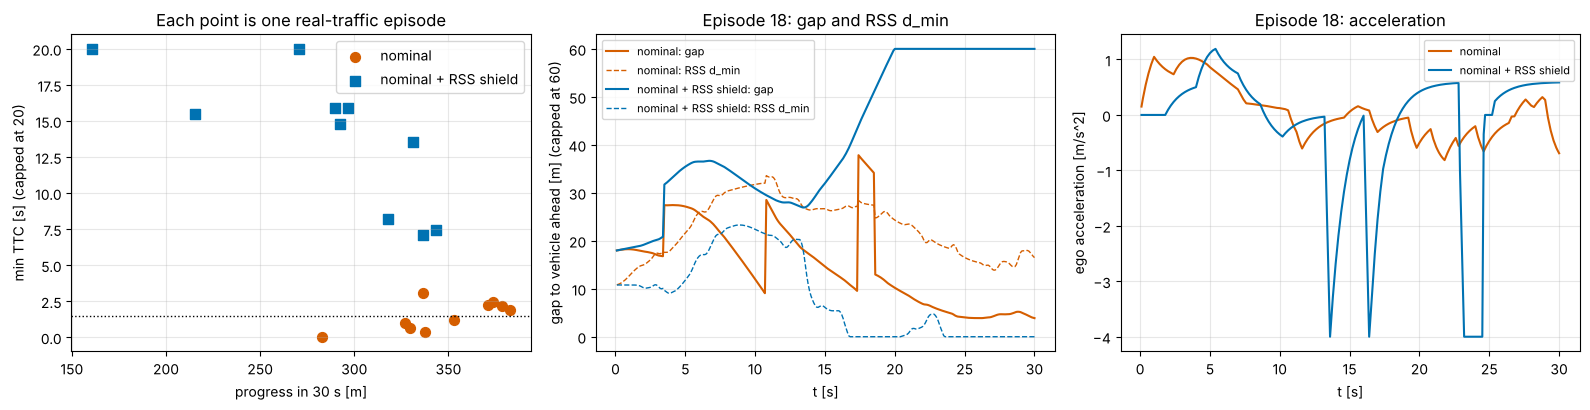

Text summary (computed from the table above):
- Collisions: nominal 1/10, shielded 0/10.
- Median of the per-episode minimum TTC: nominal 1.54 s, shielded 15.15 s; episodes below 1.5 s: 5 vs 0.
- Time inside the RSS distance: 83 % vs 0 %.
- Progress: 347 m vs 285 m (18 % less with the shield).
- Comfort: mean RMS jerk 0.58 vs 1.37 m/s^3 (higher with the shield).
- Demand on others: mean maximum deceleration of reactive followers 7.3 vs 5.6 m/s^2 (not higher with the shield).
- Shield: the nominal choice was replaced in 78 % of the steps, the fallback brake was active in 4 %.


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name, col in zip(CONFIGS, [OI["red"], OI["blue"]]):
    sub = res[res.configuration == name]
    ax[0].scatter(sub["progress [m]"], np.minimum(sub["min TTC [s]"], 20), color=col, s=50, label=name,
                  marker="o" if name == "nominal" else "s")
ax[0].axhline(1.5, color=OI["black"], ls=":", lw=1)
ax[0].set(xlabel="progress in 30 s [m]", ylabel="min TTC [s] (capped at 20)", title="Each point is one real-traffic episode")
ax[0].legend()
ep_show = EPISODES[1]
for name, col in zip(CONFIGS, [OI["red"], OI["blue"]]):
    lg = traces[(ep_show, name)]
    ax[1].plot(lg.t, np.minimum(lg.gap, 60), color=col, label=f"{name}: gap")
    ax[1].plot(lg.t, lg.d_min, color=col, ls="--", lw=1, label=f"{name}: RSS d_min")
    ax[2].plot(lg.t, lg.a, color=col, label=name)
ax[1].set(xlabel="t [s]", ylabel="gap to vehicle ahead [m] (capped at 60)", title=f"Episode {ep_show}: gap and RSS d_min")
ax[2].set(xlabel="t [s]", ylabel="ego acceleration [m/s^2]", title=f"Episode {ep_show}: acceleration")
ax[1].legend(fontsize=8); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

nom, shd = (summary[c] for c in CONFIGS)
print("Text summary (computed from the table above):")
print(f"- Collisions: nominal {int(nom['collisions'])}/{int(nom['episodes'])}, shielded {int(shd['collisions'])}/{int(shd['episodes'])}.")
print(f"- Median of the per-episode minimum TTC: nominal {nom['median min TTC [s]']:.2f} s, shielded {shd['median min TTC [s]']:.2f} s; "
      f"episodes below 1.5 s: {int(nom['episodes with min TTC < 1.5 s'])} vs {int(shd['episodes with min TTC < 1.5 s'])}.")
print(f"- Time inside the RSS distance: {nom['mean time RSS-unsafe [%]']:.0f} % vs {shd['mean time RSS-unsafe [%]']:.0f} %.")
print(f"- Progress: {nom['mean progress [m]']:.0f} m vs {shd['mean progress [m]']:.0f} m "
      f"({100 * (1 - shd['mean progress [m]'] / nom['mean progress [m]']):.0f} % less with the shield).")
print(f"- Comfort: mean RMS jerk {nom['mean RMS jerk [m/s^3]']:.2f} vs {shd['mean RMS jerk [m/s^3]']:.2f} m/s^3 "
      f"({'higher' if shd['mean RMS jerk [m/s^3]'] > nom['mean RMS jerk [m/s^3]'] else 'lower'} with the shield).")
print(f"- Demand on others: mean maximum deceleration of reactive followers {nom['mean max decel imposed [m/s^2]']:.1f} vs "
      f"{shd['mean max decel imposed [m/s^2]']:.1f} m/s^2 ({'higher' if shd['mean max decel imposed [m/s^2]'] > nom['mean max decel imposed [m/s^2]'] else 'not higher'} with the shield).")
print(f"- Shield: the nominal choice was replaced in {res[res.configuration == 'nominal + RSS shield']['shield interventions [%]'].mean():.0f} % "
      f"of the steps, the fallback brake was active in {res[res.configuration == 'nominal + RSS shield']['fallback active [%]'].mean():.0f} %.")

**Reading the results.**

- The nominal planner checks only for *overlap* with constant-velocity predictions and a 0.5 m margin. In stop-and-go traffic that is not enough: when a leader brakes harder than predicted, the ego ends up at very short TTC, and the margin is consumed. The planner is "collision-free" with respect to its predictions, not with respect to reality.
- The shield keeps the ego outside the RSS distance almost all the time. When it cannot find an admissible candidate it hands over to the proper response, a jerk-limited brake in lane; these handovers show up in the RMS jerk. Whether the shield's braking increases the demand on following traffic is visible in the last row; Section 8 examines this risk transfer with real follower gaps.
- The price is **progress**: the envelope demands longer gaps than the surrounding drivers keep (Section 2.1). A real deployment would justify $(\rho, b_{\min}, b_{\max})$ for the ODD and give the nominal planner the same envelope as a constraint, so that the shield rarely has to act. A shield that intervenes most of the time is a sign that the nominal planner and the envelope encode different assumptions.

> Ten episodes are enough to show mechanisms, not to estimate rates. Collision rates for a safety case need many orders of magnitude more exposure ([06/08](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb)).

## 7. Chance constraints and the freezing robot

The shield above uses a deterministic check with small fixed margins plus RSS. The alternative is to put the prediction uncertainty into the planner's hard constraint: reject a candidate if its overlap probability with any agent exceeds $\delta$ at any time. We run the planner *without* the shield for three values of $\delta$ on three episodes.

In [12]:
rows = []
for ep in EPISODES[:3]:
    for DELTA in (0.2, 0.05, 0.01):
        log, info = run_episode(ep, dict(constraint="chance", shield=False))
        rows.append({"episode": ep, "delta": DELTA, "progress [m]": log.s.iloc[-1] - log.s.iloc[0],
                     "min TTC [s]": log.ttc.min(), "collision": info["collision"]["cause"] if info["collision"] else "none"})
DELTA = 0.01
cc = pd.DataFrame(rows)
display(cc.pivot(index="episode", columns="delta", values="progress [m]").round(0).add_prefix("progress [m], delta = "))
g = cc.groupby("delta")["progress [m]"].mean()
print(f"Mean progress: delta 0.2 -> {g[0.2]:.0f} m, 0.05 -> {g[0.05]:.0f} m, 0.01 -> {g[0.01]:.0f} m.")

delta,"progress [m], delta = 0.01","progress [m], delta = 0.05","progress [m], delta = 0.2"
episode,,,
15,23.0,350.0,368.0
18,24.0,355.0,360.0
21,30.0,327.0,329.0


Mean progress: delta 0.2 -> 352 m, 0.05 -> 344 m, 0.01 -> 26 m.


At small $\delta$ the planner stops almost immediately: in dense traffic, *every* trajectory, including standing still, has a small probability of overlapping with some neighbour that might change lanes. This is the **freezing robot problem** (Trautman & Krause, 2010): independent per-agent uncertainty that grows with the horizon eventually covers all free space. A stopped vehicle in a moving motorway lane is not safe either.

Practical consequences: (i) the risk measure must be compared with the risk of the alternatives, including stopping; (ii) responsibility models such as RSS are one way to decide which uncertainty the ego must cover (a vehicle that cuts in is responsible for doing so with a safe distance); (iii) interaction-aware prediction reduces uncertainty because other drivers react to the ego. The value of $\delta$ is a safety requirement that needs a rationale, not a tuning parameter.

## 8. Fallback and minimal risk manoeuvres

### 8.1 Comfort limits from real driving (KITTI GPS/IMU)

Before choosing MRM decelerations we look at what a human driver does. The KITTI tracking sequences contain the OXTS GPS/IMU record at 10 Hz. We parse the raw text files directly (30 values per line; forward acceleration `af` is column 15, lateral acceleration `al` column 16, forward speed `vf` column 9), smooth the accelerations over 0.5 s and differentiate for jerk.

,braking [m/s^2],acceleration [m/s^2],|lateral acc.| [m/s^2],|jerk| [m/s^3]
median,0.30,0.42,0.11,0.27
95th pct,1.81,1.35,1.57,1.55
99th pct,2.19,1.74,2.30,2.71
max,2.78,2.33,3.34,5.46


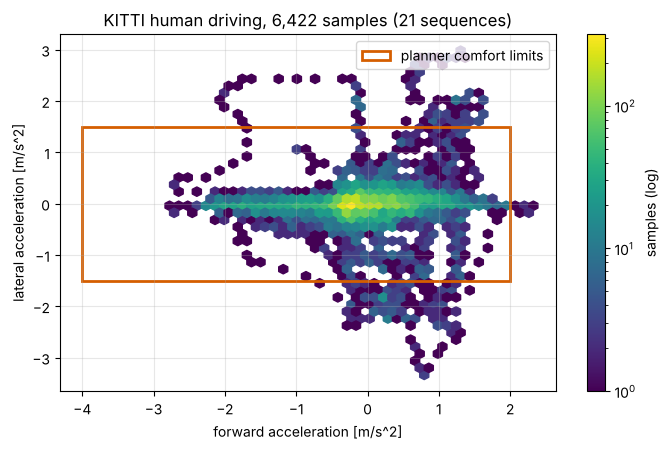

94.5% of the human samples lie inside the planner's comfort limits; the 99th percentile of braking is 2.2 m/s^2.


In [13]:
oxts = []
try:
    for seq in range(21):
        txt = D.fetch_kitti_file("data_tracking_oxts.zip", f"training/oxts/{seq:04d}.txt").decode()
        a = np.loadtxt(txt.splitlines())
        sm = lambda x: np.convolve(x, np.ones(5) / 5, mode="same")
        af, al = sm(a[:, 14]), sm(a[:, 15])
        oxts.append(pd.DataFrame({"seq": seq, "v": a[:, 8], "af": af, "al": al, "jerk": np.gradient(af, 0.1)}).iloc[3:-3])
    oxts = pd.concat(oxts, ignore_index=True)
    mov = oxts[oxts.v > 1.0]
    kitti_ok = True
except D.DataUnavailable as exc:
    kitti_ok = False
    print(f"KITTI OXTS unavailable ({exc}); Section 8.1 is skipped.")

if kitti_ok:
    stats = pd.DataFrame({
        "braking [m/s^2]": np.percentile(-mov.af[mov.af < 0], [50, 95, 99, 100]),
        "acceleration [m/s^2]": np.percentile(mov.af[mov.af > 0], [50, 95, 99, 100]),
        "|lateral acc.| [m/s^2]": np.percentile(np.abs(mov.al), [50, 95, 99, 100]),
        "|jerk| [m/s^3]": np.percentile(np.abs(mov.jerk), [50, 95, 99, 100])},
        index=["median", "95th pct", "99th pct", "max"]).round(2)
    display(stats)
    fig, ax = plt.subplots(figsize=(7, 4.6))
    hb = ax.hexbin(mov.af, mov.al, gridsize=40, mincnt=1, bins="log", cmap="viridis")
    ax.add_patch(Rectangle((-LIMITS["a_dec"], -LIMITS["a_lat"]), LIMITS["a_dec"] + LIMITS["a_acc"], 2 * LIMITS["a_lat"],
                           fill=False, ec=OI["red"], lw=2, label="planner comfort limits"))
    ax.set(xlabel="forward acceleration [m/s^2]", ylabel="lateral acceleration [m/s^2]",
           title=f"KITTI human driving, {len(mov):,} samples (21 sequences)")
    plt.colorbar(hb, label="samples (log)"); ax.legend(); plt.tight_layout(); plt.show()
    inside = ((mov.af <= LIMITS["a_acc"]) & (mov.af >= -LIMITS["a_dec"]) & (np.abs(mov.al) <= LIMITS["a_lat"])).mean()
    print(f"{inside:.1%} of the human samples lie inside the planner's comfort limits; the 99th percentile of braking is "
          f"{stats.loc['99th pct', 'braking [m/s^2]']:.1f} m/s^2.")

The human driver in these urban and rural sequences rarely brakes harder than about 2–3 m/s² and the lateral accelerations stay mostly below the 1.5 m/s² limit: the planner's limits are in the range of normal human driving, and an in-lane MRM at 2 m/s² would feel like ordinary traffic braking. (Sample: one driver, one city, 21 short sequences; comfort limits for a product need a broader study.)

### 8.2 Three in-lane stops

| MRM | Deceleration | Jerk limit | Rationale |
|---|---|---|---|
| **Comfort stop** | 2 m/s² | 2 m/s³ | Inside normal human braking (8.1); predictable for followers |
| **R157-style stop** | 4 m/s² | 4 m/s³ | UN R157 aims at an MRM deceleration not exceeding 4.0 m/s² for an ALKS (see [07/01](01_odd_and_runtime_monitoring.ipynb)) |
| **Emergency stop** | 8 m/s² | 30 m/s³ | Close to the friction limit on dry asphalt; the RSS $b_{\max}$ assumed for others |

ISO 23793-1:2024 defines the framework for minimal risk manoeuvres and specifies the two simplest types, a **straight stop** and an **in-lane stop**; manoeuvres that change lane to reach the hard shoulder are more capable but need perception and a gap in the target lane, which is exactly what may be degraded when the MRM is triggered. The question for each profile is not only how far the ego travels, but what it demands from the vehicle behind.

initial speed [km/h],stopping distance [m] from 50 km/h,stopping distance [m] from 100 km/h,stopping distance [m] from 130 km/h
MRM,,,
R157-style stop,31.0,110.0,181.0
comfort stop,55.0,207.0,344.0
emergency stop,14.0,52.0,86.0


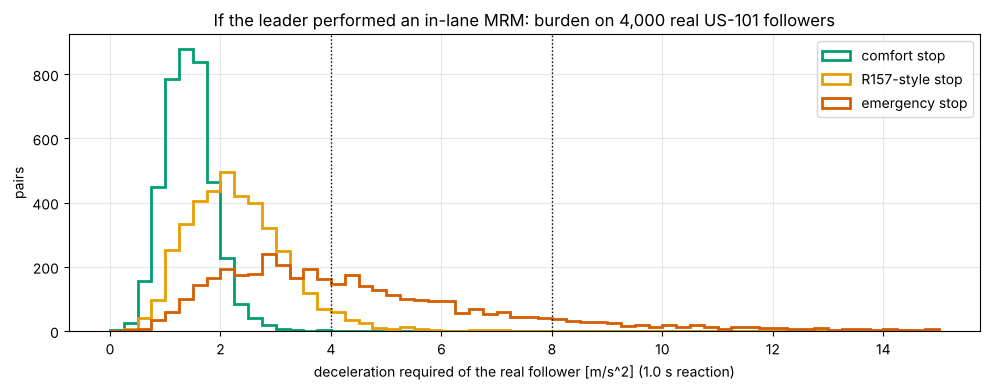

,median [m/s^2],share > 4 m/s^2,share > 8 m/s^2
comfort stop,1.42,0.00,0.00
R157-style stop,2.22,0.05,0.00
emergency stop,3.96,0.49,0.13


An emergency stop would demand more than 8 m/s^2 (beyond typical friction limits) from 13% of the real followers, a comfort stop from 0%.


In [14]:
def stop_profile(v0, b, jerk, t_end=25.0, dt=0.05):
    t = np.arange(0, t_end, dt)
    a = np.maximum(-b, -jerk * t)
    v = np.maximum(v0 + np.cumsum(a) * dt, 0.0)
    return t, v, np.cumsum(v) * dt

def follower_required_decel(gap, v_f, v_l, b, jerk, reaction=1.0, dt=0.05, t_end=25.0):
    # Smallest constant deceleration of a follower (reacting after `reaction` s) that avoids hitting a leader
    # executing the given stop profile; vectorised over pairs by bisection.
    t = np.arange(0, t_end, dt)
    a = np.maximum(-b, -jerk * t)
    vl = np.maximum(v_l[:, None] + np.cumsum(a)[None, :] * dt, 0.0)
    xl = gap[:, None] + np.cumsum(vl, axis=1) * dt
    lo, hi = np.zeros(len(gap)), np.full(len(gap), 30.0)
    tr = np.clip(t - reaction, 0, None)[None, :]
    for _ in range(30):
        mid = 0.5 * (lo + hi)
        t_stop = v_f[:, None] / mid[:, None]
        tb = np.minimum(tr, t_stop)
        xf = v_f[:, None] * np.minimum(t, reaction)[None, :] + v_f[:, None] * tb - 0.5 * mid[:, None] * tb**2
        ok = (xl - xf >= 0).all(axis=1)
        hi, lo = np.where(ok, mid, hi), np.where(ok, lo, mid)
    return hi

rows = []
for name, (b, jerk) in MRM.items():
    for v0_kmh in (50, 100, 130):
        t, v, x = stop_profile(v0_kmh / 3.6, b, jerk)
        rows.append({"MRM": name, "initial speed [km/h]": v0_kmh, "time to stop [s]": t[np.argmax(v <= 0)],
                     "stopping distance [m]": x[-1]})
display(pd.DataFrame(rows).pivot(index="MRM", columns="initial speed [km/h]", values="stopping distance [m]")
        .round(0).add_prefix("stopping distance [m] from ").add_suffix(" km/h"))

# Real follower-leader pairs from Section 2.1: what would each MRM demand from the real follower?
P = pairs.sample(min(4000, len(pairs)), random_state=0)
burden = {name: follower_required_decel(P.gap.to_numpy(), P.v_f.to_numpy(), P.v_l.to_numpy(), b, j)
          for name, (b, j) in MRM.items()}
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 15, 61)
for (name, req), col in zip(burden.items(), [OI["green"], OI["orange"], OI["red"]]):
    ax.hist(req, bins=bins, histtype="step", lw=2, color=col, label=name)
for xv, lab in [(4.0, "4 m/s^2"), (8.0, "8 m/s^2")]:
    ax.axvline(xv, color=OI["black"], ls=":", lw=1)
ax.set(xlabel="deceleration required of the real follower [m/s^2] (1.0 s reaction)", ylabel="pairs",
       title=f"If the leader performed an in-lane MRM: burden on {len(P):,} real US-101 followers")
ax.legend(); plt.tight_layout(); plt.show()
tab = pd.DataFrame({name: {"median [m/s^2]": np.median(req), "share > 4 m/s^2": np.mean(req > 4), "share > 8 m/s^2": np.mean(req > 8)}
                    for name, req in burden.items()}).T
display(tab.round(2))
print(f"An emergency stop would demand more than 8 m/s^2 (beyond typical friction limits) from "
      f"{tab.loc['emergency stop', 'share > 8 m/s^2']:.0%} of the real followers, a comfort stop from "
      f"{tab.loc['comfort stop', 'share > 8 m/s^2']:.0%}.")

The follower is assumed to react after 1.0 s, a round value within the range of brake-reaction times reported for alerted to surprised drivers (Green, 2000). The result is the core argument for graded fallback: **an emergency stop protects the ego's front and endangers its rear**. At the short real gaps of congested traffic a large share of followers could not avoid a collision if the ego stopped at 8 m/s², whereas a comfort stop is absorbed by almost all of them. The choice of MRM is therefore a risk trade-off to be argued in the safety case, and an MRM should use the mildest profile that still resolves the hazard.

## 9. Fail-safe versus fail-operational

| Architecture | What happens when the primary path fails | Needed for | Examples of mechanisms |
|---|---|---|---|
| **Fail-silent / fail-safe** | The function switches off or brakes to a stop immediately; a safe state exists and can be reached without the failed function | Level 0–2 functions where the driver is the fallback (an AEB that switches off) | Plausibility checks, watchdogs, switch-off paths, warnings |
| **Fail-operational (fail-degraded)** | A fallback channel keeps the vehicle under control for long enough to perform an MRM; the safe state is reached *by driving*, not by switching off | Level 3–4 systems on roads where stopping instantly is not safe | Redundant power, braking and steering; a separate fallback planner/controller on independent hardware; degraded perception |
| **Simplex / shielding** | A verified safety controller and decision module supervise a complex controller at all times | Learned or otherwise hard-to-verify planners | Sections 5–6 of this notebook |

In ISO 26262 terms, a fail-operational item has a safe state that includes **emergency operation** for a specified time; the fault-tolerant time interval and the emergency operation time interval must be argued. For a Level 3 ALKS under UN R157 the system must also be able to perform the MRM itself if the driver does not take over.

### 9.1 Fault-injection experiment

At $t = 10$ s the primary planner fails in each of the ten episodes. We compare four reactions:

- **hold (no fallback)**: the failed primary keeps its last acceleration and lateral position (a fail-silent path that is not actually silent);
- **emergency stop**: fail-safe by braking at 8 m/s²;
- **R157-style stop** and **comfort stop**: a fail-operational fallback channel performing an in-lane MRM.

In [15]:
t_run = time.time(); rows = []
for ep in EPISODES:
    for mode in ["hold", "emergency stop", "R157-style stop", "comfort stop"]:
        log, info = run_episode(ep, CONFIGS["nominal"], fault_at=10.0, fault_mode=mode)
        after = log[log.t > 10.0]
        rows.append({"episode": ep, "reaction to the fault": mode,
                     "collision": info["collision"]["cause"] if info["collision"] else "none",
                     "max decel imposed on others [m/s^2]": info["max_imposed"],
                     "distance after fault [m]": after.s.iloc[-1] - after.s.iloc[0] if len(after) else 0.0,
                     "stopped": bool(len(after) and after.v.iloc[-1] < 0.1)})
fi = pd.DataFrame(rows)
order = ["hold", "emergency stop", "R157-style stop", "comfort stop"]
fsum = fi.groupby("reaction to the fault").agg(**{
    "collisions (of 10)": ("collision", lambda x: int((x != "none").sum())),
    "reached standstill (of 10)": ("stopped", "sum"),
    "median distance after fault [m]": ("distance after fault [m]", "median"),
    "mean max decel imposed on others [m/s^2]": ("max decel imposed on others [m/s^2]", "mean"),
    "episodes imposing >= 6 m/s^2": ("max decel imposed on others [m/s^2]", lambda x: int((x >= 6).sum()))}).loc[order]
display(fsum.round(2))
display(fi[fi.collision != "none"][["episode", "reaction to the fault", "collision"]])
print(f"{len(fi)} fault-injection runs in {time.time() - t_run:.0f} s.")
h, em, cm = fsum.loc["hold"], fsum.loc["emergency stop"], fsum.loc["comfort stop"]
print(f"Holding the last command led to {int(h['collisions (of 10)'])} collisions in 10 episodes. "
      f"Emergency stop: {int(em['collisions (of 10)'])} collisions, deceleration imposed on reactive followers "
      f"{em['mean max decel imposed on others [m/s^2]']:.1f} m/s^2 on average; comfort stop: "
      f"{int(cm['collisions (of 10)'])} collisions, {cm['mean max decel imposed on others [m/s^2]']:.1f} m/s^2.")

,collisions (of 10),reached standstill (of 10),median distance after fault [m],mean max decel imposed on others [m/s^2],episodes imposing >= 6 m/s^2
reaction to the fault,,,,,
hold,4,0,164.28,6.15,7
emergency stop,0,10,9.74,7.87,8
R157-style stop,0,10,23.97,8.18,9
comfort stop,0,10,43.77,6.82,6


,episode,reaction to the fault,collision
4,18,hold,ego ran into a vehicle ahead
8,21,hold,ego ran into a vehicle ahead
24,37,hold,ego ran into a vehicle ahead
28,40,hold,ego ran into a vehicle ahead


40 fault-injection runs in 28 s.
Holding the last command led to 4 collisions in 10 episodes. Emergency stop: 0 collisions, deceleration imposed on reactive followers 7.9 m/s^2 on average; comfort stop: 0 collisions, 6.8 m/s^2.


Interpretation, with the caveats of a ten-episode replay:

- A primary path that fails **without** a defined fallback is the worst case. Detecting the failure (watchdogs, plausibility checks on the trajectory) is a prerequisite for any of the other rows; its coverage and latency belong to the ISO 26262 evaluation of safety mechanisms.
- Every in-lane stop on a busy road demands braking from the vehicles behind. The reactive followers here are IDM drivers that react without delay and may brake at up to 9 m/s², so they are more capable than real drivers; Section 8.2, with real gaps and a 1 s reaction time, is the more realistic picture of the risk transfer.
- An in-lane stop ends with a vehicle standing in a live lane. That is a *minimal* risk condition, not a safe one, which is why UN R157 (01 series) requires an MRM lane-change capability for operation above 60 km/h and why reaching the hard shoulder is the preferred end state where it is possible.

## 10. Limitations of this notebook

1. **Replay is not reality.** Recorded drivers do not react to the ego until they are switched to IDM; IDM is a simple, well-behaved driver model. Interaction effects (other drivers yielding or cutting in because of the ego) are missing in both directions.
2. **Perfect perception and tracking.** The planner receives the true current positions and speeds (with NGSIM's own measurement noise), and the ego follows its trajectory exactly. Perception errors and controller tracking errors would add to the prediction error.
3. **One site, one minute.** The error distribution, the RSS gap statistics and the follower burden come from 50 s of congested US-101 traffic. Other densities, road types and countries will differ.
4. **Straight road, longitudinal RSS only.** The shield uses a lateral overlap test but not the full RSS lateral rules; curved roads require Frenet projection of the agents.
5. **Small sample.** Ten episodes show mechanisms, not rates.

## In industry

**Work products fed.** The motion-planning and safety-layer parts of the **system and software architecture** (ISO 26262-4/-6), the **SOTIF analysis** of planner and prediction insufficiencies with their triggering conditions (ISO 21448, e.g. "leader brakes harder than predicted", "neighbour cuts in"), the **safety concept for the fallback** (MRM types, degradation modes, fault-tolerant and emergency operation time intervals), and the **scenario-based V&V report** with closed-loop results on recorded traffic. Assumptions of the envelope (RSS parameters) are documented against IEEE 2846-2022 and appear as claims in a UL 4600 safety case.

**Owner.** Planning and prediction engineers build the nominal planner; a separate safety-architecture or "safety layer" team owns the shield, its parameters and its verification; functional safety engineers own the fallback channel and its independence; the V&V team owns the replay and simulation evidence.

**Tools and formats.** Log-replay simulators with reactive agents (nuPlan-style closed-loop evaluation, in-house replay of fleet logs); scenario formats such as ASAM OpenSCENARIO; parameter files for the envelope under configuration management; dashboards of shield-intervention and fallback rates per software release.

**Typical review findings**
- Safety requirements implemented as cost weights, so that progress or comfort terms can outweigh them.
- Envelope parameters copied from a paper, with no evidence that they are reasonable for the ODD or achievable by the vehicle (actual $b_{\min}$ on wet roads).
- Fallback tested only at the unit level, never in closed loop with following traffic; no analysis of rear-end risk created by the MRM.
- Shield and nominal planner share the same prediction module or the same hardware, so a common-cause failure defeats both.
- Evaluation only open-loop (displacement errors) or with non-reactive agents, without stating the limitation.

**What an assessor checks:** that hard constraints and the shield trace to safety requirements; that the shield's assumptions are listed and monitored in operation (e.g. observed decelerations of other road users versus $b_{\max}$); that intervention and fallback rates are tracked as safety performance indicators; that the MRM selection is justified by a risk comparison including following traffic; and that the fallback channel is sufficiently independent of the primary path.

## Key takeaways

- Route, behaviour and motion planning contribute different safety properties; none of them can be safer than the predictions it relies on.
- A Frenet lattice planner is a few dozen lines of code: quintic lateral and quartic longitudinal polynomials, kinematic limits and collision checks as **hard constraints**, comfort and progress as **costs**.
- Constant-velocity prediction errors on real US-101 data grow to several metres within 3 s; inflating occupancy or chance constraints turns this into planning margins, and too small a $\delta$ freezes the vehicle.
- An **RSS shield** in a **Simplex** arrangement reduced critical encounters in real-traffic replay, at the cost of progress and harsher fallback braking; with default parameters RSS is much more conservative than real drivers in congestion.
- **Emergency stops shift risk to the rear**: with real gaps, a large share of followers could not avoid an 8 m/s² stop, while a 2 m/s² stop is absorbed by nearly all.
- Fail-operational systems need a detected failure, an independent fallback channel and a justified MRM; holding the last command is the worst option.

## Self-assessment

1. Which planning layer is responsible for keeping the vehicle inside its ODD, and which for kinematic feasibility?
2. Why should collision avoidance be a hard constraint rather than a large cost term?
3. What does the 95th percentile of the CV prediction error at 3 s mean for the margin a planner needs, and why is the lateral error smaller than the longitudinal one?
4. Explain the freezing robot problem in the words of this notebook's experiment.
5. In the Simplex architecture, what are the three components, and which of them must be verified to a high integrity level?
6. Why did the shielded planner make less progress, and what would you change to reduce its intervention rate without weakening the guarantee?
7. Why can an emergency stop be the more dangerous MRM? Which data did we use to show it?
8. Distinguish fail-safe and fail-operational, and give one requirement that only the latter has.

<details>
<summary><b>Show answers</b></summary>

1. Route planning keeps the trip on roads inside the ODD; the motion planner ensures kinematic feasibility (and the controller tracks the trajectory).
2. A cost can be outweighed by other terms (progress, comfort) and its effect depends on the weights; a hard constraint is either satisfied or the candidate is rejected, and it can be verified independently of the cost tuning.
3. To keep 95 % of the predicted positions outside the ego's footprint at 3 s, the predicted box must be enlarged by about that amount (several metres longitudinally). Lateral motion is restricted by lanes and lane changes are rare, so lateral errors stay small except during lane changes.
4. With $\delta = 0.01$ every candidate, including stopping, has an overlap probability above 1 % with some neighbour within 5 s, because the lateral and longitudinal uncertainty of many agents together covers the free space; the planner rejects everything and the vehicle stops in a live lane.
5. A high-performance (complex) controller, a high-assurance safety controller and a decision module. The safety controller and the decision module must be verified; the complex controller need not be, as long as the decision module keeps the system in the recoverable region.
6. The RSS parameters require gaps far longer than real drivers keep, so the shield often vetoes or brakes. Options: justify less conservative parameters for the ODD (e.g. $b_{\max}$ from observed braking, a shorter $\rho$ for a fast system), give the nominal planner the same envelope as a constraint so that the shield rarely needs to act, and treat responsibility rules (who must keep the distance) explicitly.
7. Following drivers keep short gaps and react late; if the ego stops at 8 m/s², the follower needs more deceleration than is physically available. We used real follower-leader gaps and speeds from NGSIM and a 1.0 s reaction time.
8. Fail-safe: a safe state can be reached by switching off or stopping immediately. Fail-operational: the system must continue to operate, possibly degraded, until an MRM is complete; it needs, for example, an emergency operation time interval and a fallback path independent of the failed one.

</details>

## References

- Alshiekh, M., Bloem, R., Ehlers, R., Könighofer, B., Niekum, S., Topcu, U. (2018). Safe reinforcement learning via shielding. *Proceedings of the AAAI Conference on Artificial Intelligence*, 32(1). https://doi.org/10.1609/aaai.v32i1.11797
- Blackmore, L., Ono, M., Williams, B. C. (2011). Chance-constrained optimal path planning with obstacles. *IEEE Transactions on Robotics*, 27(6), 1080–1094. https://doi.org/10.1109/TRO.2011.2161160
- Caesar, H., Kabzan, J., Tan, K. S., Fong, W. K., Wolff, E., et al. (2021). nuPlan: A closed-loop ML-based planning benchmark for autonomous vehicles. arXiv:2106.11810. https://arxiv.org/abs/2106.11810
- Coifman, B., Li, L. (2017). A critical evaluation of the Next Generation Simulation (NGSIM) vehicle trajectory dataset. *Transportation Research Part B*, 105, 362–377. https://doi.org/10.1016/j.trb.2017.09.018
- Geiger, A., Lenz, P., Stiller, C., Urtasun, R. (2013). Vision meets robotics: The KITTI dataset. *The International Journal of Robotics Research*, 32(11), 1231–1237. https://doi.org/10.1177/0278364913491297
- Green, M. (2000). "How long does it take to stop?" Methodological analysis of driver perception-brake times. *Transportation Human Factors*, 2(3), 195–216. https://doi.org/10.1207/STHF0203_1
- IEEE 2846-2022. *IEEE Standard for Assumptions in Safety-Related Models for Automated Driving Systems*. https://standards.ieee.org/ieee/2846/10831/
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. ISO 26262:2018. *Road vehicles — Functional safety*. International Organization for Standardization.
- ISO 23793-1:2024. *Intelligent transport systems — Minimal risk manoeuvre (MRM) for automated driving — Part 1: Framework, straight-stop and in-lane stop*. https://www.iso.org/standard/81711.html
- Magdici, S., Althoff, M. (2016). Fail-safe motion planning of autonomous vehicles. *2016 IEEE 19th International Conference on Intelligent Transportation Systems (ITSC)*, 452–458. https://doi.org/10.1109/ITSC.2016.7795594
- Paden, B., Čáp, M., Yong, S. Z., Yershov, D., Frazzoli, E. (2016). A survey of motion planning and control techniques for self-driving urban vehicles. *IEEE Transactions on Intelligent Vehicles*, 1(1), 33–55. https://doi.org/10.1109/TIV.2016.2578706
- Patel, M., Khatun, M., Jung, R., Glaß, M. (2021). Simulation-based analysis of highway trajectory planning using high-order polynomial for highly automated driving function. *ICECCME 2021*. https://doi.org/10.1109/ICECCME52200.2021.9591044
- Pek, C., Manzinger, S., Koschi, M., Althoff, M. (2020). Using online verification to prevent autonomous vehicles from causing accidents. *Nature Machine Intelligence*, 2, 518–528. https://doi.org/10.1038/s42256-020-0225-y
- Sha, L. (2001). Using simplicity to control complexity. *IEEE Software*, 18(4), 20–28. https://doi.org/10.1109/MS.2001.936213
- Shalev-Shwartz, S., Shammah, S., Shashua, A. (2017). On a formal model of safe and scalable self-driving cars. arXiv:1708.06374. https://arxiv.org/abs/1708.06374
- Trautman, P., Krause, A. (2010). Unfreezing the robot: Navigation in dense, interacting crowds. *2010 IEEE/RSJ International Conference on Intelligent Robots and Systems (IROS)*, 797–803. https://doi.org/10.1109/IROS.2010.5654369
- Treiber, M., Hennecke, A., Helbing, D. (2000). Congested traffic states in empirical observations and microscopic simulations. *Physical Review E*, 62(2), 1805–1824. https://doi.org/10.1103/PhysRevE.62.1805
- UL 4600 (3rd ed., 2023). *Standard for Evaluation of Autonomous Products*. UL Standards & Engagement.
- UN Regulation No. 157 — Automated Lane Keeping Systems, 01 series of amendments (ECE/TRANS/WP.29/2022/59/Rev.1).
- US Department of Transportation, Federal Highway Administration. *Next Generation Simulation (NGSIM) Vehicle Trajectories and Supporting Data*, US-101 subset. Public domain. https://data.transportation.gov/d/8ect-6jqj
- Werling, M., Ziegler, J., Kammel, S., Thrun, S. (2010). Optimal trajectory generation for dynamic street scenarios in a Frenét frame. *2010 IEEE International Conference on Robotics and Automation (ICRA)*, 987–993. https://doi.org/10.1109/ROBOT.2010.5509799

In [16]:
print(f"Notebook executed in {time.time() - T0:.0f} s.")

Notebook executed in 94 s.


---
**Navigation:** ← [01 ODD and runtime monitoring](01_odd_and_runtime_monitoring.ipynb) · [Module index](README.md) · [03 Human factors and takeover](03_human_factors_and_takeover.ipynb) →